# CS461 Final — Automated Produce Quality Inspector
**Custom CNN · Model Tuning & Optimization: Adam vs SGD+Momentum**

ขั้นตอน: **Baseline** (LR คงที่ จาก check-in) → **Tuning** (LR 3 ค่า × constant/cosine ต่อ optimizer = 12 runs, seed เดียวกันทุก run)
→ เลือก setup ที่ดีที่สุดของแต่ละ optimizer ด้วย **validation loss** → รายงานผล **clean test เท่านั้น** (ก่อน vs หลัง tuning)

รันใน **Kaggle Notebook (GPU T4 + Add Data: sriramr/fruits-fresh-and-rotten-for-classification)** หรือ **Google Colab (T4 GPU)**
กด *Run all* / *Save & Run All* ครั้งเดียว ทุกกราฟ/ตารางจะถูกบันทึกไว้ใน `outputs/` (บน Colab = Google Drive → `MyDrive/cs461_final/outputs`)

**ถ้าหลุดกลางทาง:** Run all ใหม่ได้เลย ส่วนที่เสร็จแล้ว (hash, run ที่เทรนจบ) จะถูกข้าม

ใช้เวลาประมาณ 2.5–3.5 ชม. บน T4 (12 runs × ~10–15 นาที) · `quick=True` = smoke test ไม่กี่นาที

In [1]:
!pip -q install imagehash kagglehub

## 0. Config

In [2]:
import os, random, time, json, math
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import imagehash
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, f1_score, recall_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

CFG = dict(
    data_root=None,      # None = หาให้อัตโนมัติ / หรือใส่ path ที่มีโฟลเดอร์ train/ และ test/
    img_size=224, cache_size=256,
    batch_size=32, epochs=20, patience=5, seed=42,
    weight_decay=1e-4, dropout=0.4,
    dedup_hamming=0,     # 0 = fingerprint ต้องตรงกันเป๊ะ (ทดสอบแล้ว: ไม่มีกลุ่มที่ปนหลายคลาส)
    val_folds=7,         # 1/7 ≈ 14% ของ train เป็น validation
    num_workers=2,
    quick=False,         # True = smoke test (ภาพน้อย, 2 epochs) ไว้เช็กว่าโค้ดรันได้
)
CLASSES = ['freshapples','freshbanana','freshoranges','rottenapples','rottenbanana','rottenoranges']
ROTTEN = {3, 4, 5}
if Path('/var/colab/hostname').exists():      # Colab จริง: เก็บผลลง Google Drive กันหายตอนหลุด
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/cs461_final')
elif Path('/kaggle/working').exists():         # Kaggle: ไฟล์ใน /kaggle/working จะโผล่ในแท็บ Output
    BASE = Path('/kaggle/working')
else:                                          # Mac / เครื่องตัวเอง
    BASE = Path('.')
OUT = BASE / 'outputs'; OUT.mkdir(parents=True, exist_ok=True)

DEVICE = ('cuda' if torch.cuda.is_available()
          else 'mps' if torch.backends.mps.is_available()   # Apple Silicon Mac (M1/M2/M3/M4)
          else 'cpu')
if DEVICE != 'cuda':
    CFG['num_workers'] = 0          # Mac/CPU ใน notebook: worker process มักพัง
if DEVICE == 'cpu':                 # ไม่มี GPU: ลดภาพเหลือ 128px + epochs น้อยลง (เร็วขึ้น ~3 เท่า)
    CFG.update(img_size=128, cache_size=144, epochs=12, patience=4)
    print('⚠️ No GPU: using 128px images and max 12 epochs. Mention this on your slides.')
AMP = DEVICE == 'cuda'
CACHE = Path(f"/tmp/fruit_cache_{CFG['cache_size']}"); CACHE.mkdir(exist_ok=True)

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.benchmark = False      # deterministic: same seed → same result
    torch.backends.cudnn.deterministic = True
seed_everything(CFG['seed'])
print('device:', DEVICE)

device: cuda


## 1. Load dataset

In [3]:
def find_root(starts):
    for d in starts:
        d = Path(d)
        if not d.exists(): continue
        for p in d.rglob('train'):
            if p.is_dir() and (p.parent/'test').is_dir() and all((p/c).is_dir() for c in CLASSES):
                return p.parent
    return None

root = Path(CFG['data_root']) if CFG['data_root'] else find_root(['/kaggle/input', '.'])
if root is None:
    import kagglehub   # ดาวน์โหลดจาก Kaggle (ถ้าโดนถาม auth ให้ตั้ง kaggle.json ตาม README ของ kagglehub)
    root = find_root([kagglehub.dataset_download('sriramr/fruits-fresh-and-rotten-for-classification')])
print('data root:', root)

def list_images(split):
    rows = []
    for i, c in enumerate(CLASSES):
        for f in sorted((root/split/c).iterdir()):
            if f.suffix.lower() in {'.png', '.jpg', '.jpeg'}:
                rows.append((str(f), i, split))
    return pd.DataFrame(rows, columns=['path', 'label', 'split'])

df = pd.concat([list_images('train'), list_images('test')], ignore_index=True)
if CFG['quick']:
    df = df.groupby(['split', 'label']).sample(frac=1, random_state=0).groupby(['split', 'label']).head(40).reset_index(drop=True)
    CFG['epochs'] = 2
print(len(df), 'images')

data root: /kaggle/input/datasets/sriramr/fruits-fresh-and-rotten-for-classification/dataset
13599 images


## 2. EDA

split,test,train
freshapples,395,1693
freshbanana,381,1581
freshoranges,388,1466
rottenapples,601,2342
rottenbanana,530,2224
rottenoranges,403,1595


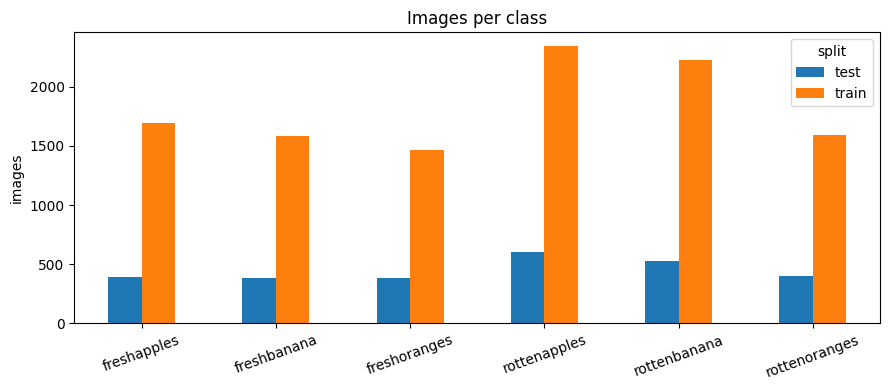

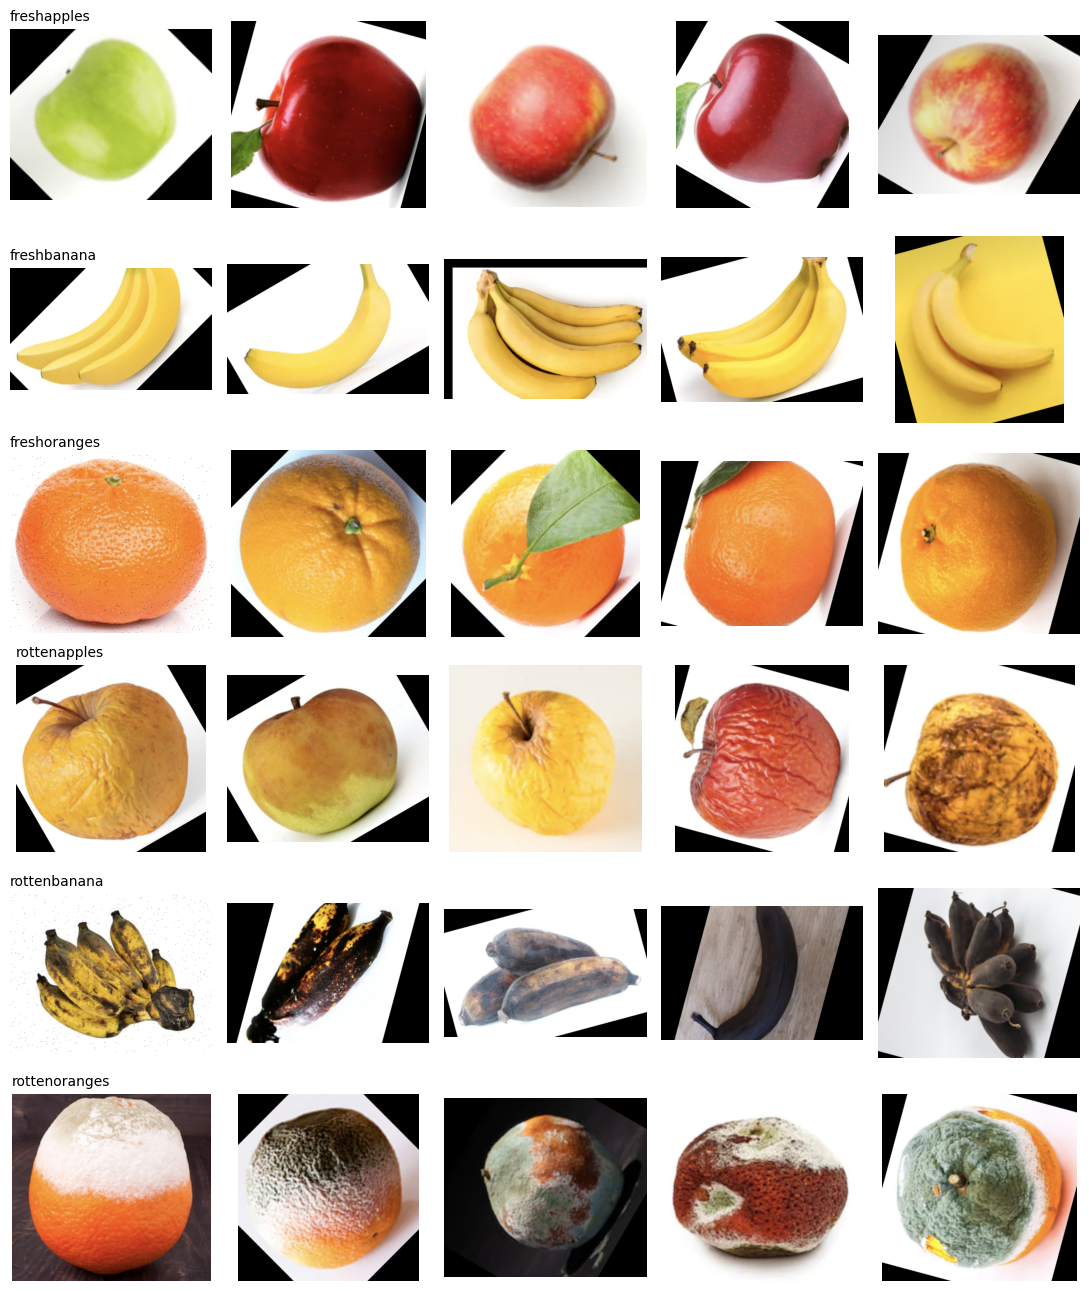

image size (w,h) min [146 116] median [402. 364.] max [840 496]


In [4]:
counts = df.pivot_table(index='label', columns='split', values='path', aggfunc='count')
counts.index = CLASSES
display(counts)
ax = counts.plot.bar(figsize=(9, 4), rot=20, title='Images per class')
ax.set_ylabel('images'); plt.tight_layout(); plt.savefig(OUT/'01_class_counts.png', dpi=150); plt.show()

fig, axes = plt.subplots(len(CLASSES), 5, figsize=(11, 13))
for r, c in enumerate(CLASSES):
    sample = df[(df.label == r) & (df.split == 'train')].sample(5, random_state=1)
    for k, p in enumerate(sample.path):
        axes[r, k].imshow(Image.open(p).convert('RGB')); axes[r, k].axis('off')
    axes[r, 0].set_title(c, loc='left', fontsize=10)
plt.tight_layout(); plt.savefig(OUT/'02_samples.png', dpi=120); plt.show()

sizes = np.array([Image.open(p).size for p in df.path.sample(min(500, len(df)), random_state=0)])
print('image size (w,h) min', sizes.min(0), 'median', np.median(sizes, 0), 'max', sizes.max(0))

## 3. Resize cache + duplicate detection (perceptual hash)
ทุกภาพถูก resize เก็บไว้ครั้งเดียว (เทรนเร็วขึ้นมาก) และคำนวณ pHash แบบ **ทนต่อการหมุน 90°/พลิก**
(เอาค่าต่ำสุดจาก 8 แบบ) แล้วจับกลุ่มภาพที่ต่างกัน ≤ `dedup_hamming` bit เป็น group เดียวกัน

0/13599 (0s)
2000/13599 (163s)
4000/13599 (329s)
6000/13599 (501s)
8000/13599 (674s)
10000/13599 (851s)
12000/13599 (1025s)
step done in 1162s
{
  "images_in_duplicate_groups": 2460,
  "pct_in_duplicate_groups": 18.1,
  "unique_groups": 12231,
  "test_images_with_near_duplicate_in_train": 437,
  "pct_test_leaked": 16.2,
  "images_in_mixed_class_groups": 4,
  "largest_group": 5
}


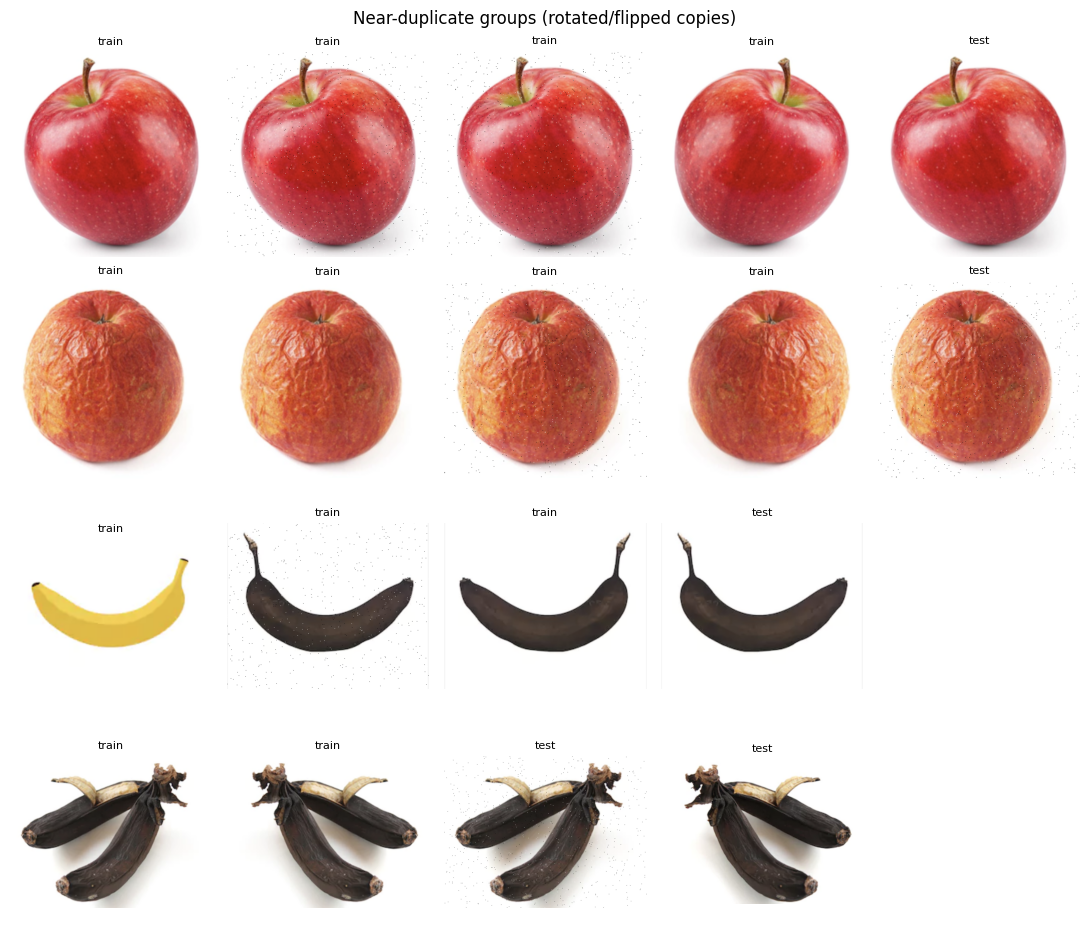

In [5]:
DIHEDRAL = [None, Image.Transpose.ROTATE_90, Image.Transpose.ROTATE_180, Image.Transpose.ROTATE_270]

HASH_FILE = OUT / f"hashes_v2_{'quick' if CFG['quick'] else 'full'}_{CFG['cache_size']}.npy"
have_hashes = HASH_FILE.exists() and len(np.load(HASH_FILE)) == len(df)

def phash_invariant(im):
    # ตัดเฉพาะกลาง 60% ของภาพ: ขอบดำจากการหมุนในชุดข้อมูลทำให้ภาพต่างผลไม้ได้ hash ใกล้กัน
    g, hs = im.convert('L').crop((int(CFG['cache_size']*.2), int(CFG['cache_size']*.2), int(CFG['cache_size']*.8), int(CFG['cache_size']*.8))), []
    for t in DIHEDRAL:
        a = g if t is None else g.transpose(t)
        for b in (a, a.transpose(Image.Transpose.FLIP_LEFT_RIGHT)):
            hs.append(int(str(imagehash.phash(b)), 16))
    return min(hs)

t0, cache_paths, hs = time.time(), [], []
for i, p in enumerate(df.path):
    out = CACHE / f'{i}.jpg'
    if not out.exists():
        Image.open(p).convert('RGB').resize((CFG['cache_size'],) * 2, Image.BILINEAR).save(out, quality=95)
    cache_paths.append(str(out))
    if not have_hashes:
        hs.append(phash_invariant(Image.open(out)))
    if i % 2000 == 0: print(f'{i}/{len(df)} ({time.time()-t0:.0f}s)')
df['cache'] = cache_paths
if have_hashes:
    hashes = np.load(HASH_FILE); print('loaded saved hashes')
else:
    hashes = np.array(hs, dtype=np.uint64); np.save(HASH_FILE, hashes)
print(f'step done in {time.time()-t0:.0f}s')

POP = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)
parent = np.arange(len(hashes))
def find(a):
    while parent[a] != a:
        parent[a] = parent[parent[a]]; a = parent[a]
    return a
for i in range(0, len(hashes), 512):
    x = np.ascontiguousarray(hashes[i:i+512, None] ^ hashes[None, :])
    d = POP[x.view(np.uint8)].reshape(x.shape[0], -1, 8).sum(-1)
    for a, b in zip(*np.nonzero(d <= CFG['dedup_hamming'])):
        a += i
        if a < b:
            ra, rb = find(a), find(b)
            if ra != rb: parent[rb] = ra
df['group'] = [find(i) for i in range(len(df))]

gsize = df.group.map(df.group.value_counts())
train_groups = set(df.loc[df.split == 'train', 'group'])
df['leak'] = (df.split == 'test') & df.group.isin(train_groups)
dup_stats = {
    'images_in_duplicate_groups': int((gsize > 1).sum()),
    'pct_in_duplicate_groups': round(float((gsize > 1).mean() * 100), 1),
    'unique_groups': int(df.group.nunique()),
    'test_images_with_near_duplicate_in_train': int(df.leak.sum()),
    'pct_test_leaked': round(float(df.leak.sum() / (df.split == 'test').sum() * 100), 1),
}
n_classes = df.groupby('group').label.nunique()
dup_stats['images_in_mixed_class_groups'] = int(df.group.isin(n_classes[n_classes > 1].index).sum())  # ควรใกล้ 0: ถ้าสูง = จับกลุ่มผิด
dup_stats['largest_group'] = int(gsize.max())
print(json.dumps(dup_stats, indent=2))

# ตัวอย่างกลุ่มภาพซ้ำ ไว้ใส่สไลด์ "Challenges"
big = df[gsize > 1].group.value_counts().head(4).index
fig, axes = plt.subplots(len(big), 5, figsize=(11, 2.4 * max(len(big), 1)), squeeze=False)
for r, g in enumerate(big):
    for k, (_, row) in enumerate(df[df.group == g].head(5).iterrows()):
        axes[r, k].imshow(Image.open(row.path).convert('RGB')); axes[r, k].set_title(row.split, fontsize=8)
    for k in range(5): axes[r, k].axis('off')
plt.suptitle('Near-duplicate groups (rotated/flipped copies)'); plt.tight_layout()
plt.savefig(OUT/'03_duplicates.png', dpi=120); plt.show()

## 4. Split train / val (stratified + group-aware) และ DataLoader

In [6]:
trn_all = df[df.split == 'train'].reset_index(drop=True)
sgkf = StratifiedGroupKFold(n_splits=CFG['val_folds'], shuffle=True, random_state=CFG['seed'])
tr_idx, va_idx = next(sgkf.split(trn_all, trn_all.label, trn_all.group))
train_df, val_df = trn_all.iloc[tr_idx], trn_all.iloc[va_idx]
test_df = df[df.split == 'test'].reset_index(drop=True)
clean_test_df = test_df[~test_df.leak]
assert not set(train_df.group) & set(val_df.group)
print(f'train {len(train_df)} | val {len(val_df)} | test {len(test_df)} | clean test {len(clean_test_df)}')

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
S = CFG['img_size']
tf_train = transforms.Compose([
    transforms.RandomResizedCrop(S, scale=(0.75, 1.0)),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.15),  # ไม่ jitter hue: สีคือสัญญาณความเน่า
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
tf_eval = transforms.Compose([transforms.Resize((S, S)), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class FruitDS(Dataset):
    def __init__(self, frame, tf): self.p, self.y, self.tf = frame.cache.tolist(), frame.label.tolist(), tf
    def __len__(self): return len(self.p)
    def __getitem__(self, i): return self.tf(Image.open(self.p[i]).convert('RGB')), self.y[i]

def loader(frame, tf, shuffle):
    g = torch.Generator().manual_seed(CFG['seed'])
    return DataLoader(FruitDS(frame, tf), batch_size=CFG['batch_size'], shuffle=shuffle, generator=g,
                      num_workers=CFG['num_workers'], pin_memory=DEVICE == 'cuda')
dl_train, dl_val = loader(train_df, tf_train, True), loader(val_df, tf_eval, False)
dl_test, dl_clean = loader(test_df, tf_eval, False), loader(clean_test_df, tf_eval, False)

train 9355 | val 1546 | test 2698 | clean test 2261


## 5. Custom CNN (ตาม proposal)
4 × [Conv2D → BatchNorm → ReLU → MaxPool] → Global Avg Pool → FC + Dropout → 6 classes

In [7]:
class FruitCNN(nn.Module):
    def __init__(self, n_classes=6, chans=(32, 64, 128, 256), p=0.4):
        super().__init__()
        layers, c_in = [], 3
        for c in chans:
            layers += [nn.Conv2d(c_in, c, 3, padding=1, bias=False), nn.BatchNorm2d(c),
                       nn.ReLU(inplace=True), nn.MaxPool2d(2)]
            c_in = c
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(p),
                                  nn.Linear(c_in, 128), nn.ReLU(inplace=True), nn.Dropout(p),
                                  nn.Linear(128, n_classes))
    def forward(self, x): return self.head(self.features(x))

n_params = sum(p.numel() for p in FruitCNN().parameters())
print(FruitCNN()); print(f'parameters: {n_params:,}')

FruitCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (13

## 6. Training loop (early stopping บน val loss)

In [8]:
@torch.no_grad()
def predict(model, dl):
    model.eval(); ys, ps, losses = [], [], []
    for x, y in dl:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE)
        with torch.autocast('cuda' if AMP else 'cpu', enabled=AMP):
            out = model(x)
        losses.append(nn.functional.cross_entropy(out.float(), y, reduction='sum').item())
        ys.append(y.cpu()); ps.append(out.float().softmax(1).cpu())
    y, p = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    return y, p, sum(losses) / len(y)

def metrics(y, p):
    pred = p.argmax(1)
    yr, pr = np.isin(y, list(ROTTEN)), np.isin(pred, list(ROTTEN))
    return dict(acc=accuracy_score(y, pred), macro_f1=f1_score(y, pred, average='macro'),
                rotten_recall=recall_score(yr, pr),               # rotten ที่จับได้ (เป้า ≥ 0.95)
                false_reject_rate=float((pr & ~yr).sum() / max((~yr).sum(), 1)))  # fresh ที่โดน reject ผิด

def train(name, make_opt, make_sched=None):
    seed_everything(CFG['seed'])
    dl_train.generator.manual_seed(CFG['seed'])   # ทุก run เห็นลำดับข้อมูลเดียวกัน (ไม่ขึ้นกับว่ารันก่อน/หลัง)
    model = FruitCNN(p=CFG['dropout']).to(DEVICE)
    opt = make_opt(model.parameters()); sched = make_sched(opt) if make_sched else None
    scaler = torch.amp.GradScaler(enabled=AMP)
    hist, best, best_state, wait = [], math.inf, None, 0
    t0 = time.time()
    for ep in range(1, CFG['epochs'] + 1):
        model.train(); tl, tc, n = 0., 0, 0
        for x, y in dl_train:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            with torch.autocast('cuda' if AMP else 'cpu', enabled=AMP):
                out = model(x); loss = nn.functional.cross_entropy(out, y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item() * len(y); tc += (out.argmax(1) == y).sum().item(); n += len(y)
        if sched: sched.step()
        yv, pv, vl = predict(model, dl_val); m = metrics(yv, pv)
        hist.append(dict(epoch=ep, train_loss=tl/n, train_acc=tc/n, val_loss=vl, val_acc=m['acc'],
                         val_f1=m['macro_f1'], lr=opt.param_groups[0]['lr']))
        pd.DataFrame(hist).to_csv(OUT/f'{name}_history.csv', index=False)
        print(f"[{name}] ep{ep:02d} train {tl/n:.3f}/{tc/n:.3f} | val {vl:.3f}/{m['acc']:.3f} F1 {m['macro_f1']:.3f}")
        if vl < best - 1e-4:
            best, wait = vl, 0; best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= CFG['patience']: print('early stop'); break
    model.load_state_dict(best_state)
    torch.save(best_state, OUT/f'{name}.pt')
    secs = time.time() - t0
    (OUT/f'{name}_done.json').write_text(json.dumps({'secs': secs}))
    return model, pd.DataFrame(hist), secs

## 7. Experiments: Baseline → LR sweep (Adam vs SGD + Momentum)
ทุก run ใช้ **model, data, augmentation, seed, epochs, early stopping, regularization เหมือนกันหมด** — เปลี่ยนแค่ optimizer / learning rate / schedule

| | Learning rates | Schedule |
|---|---|---|
| Adam | 3e-4, **1e-3**, 3e-3 | constant, cosine |
| SGD + Momentum 0.9 | 3e-3, **1e-2**, 3e-2 | constant, cosine |

ตัวหนา + constant = **baseline** จาก check-in (ผล "ก่อน tuning")
Regularization ที่ใช้ทุก run: Dropout 0.4 · L2 (weight decay 1e-4) · BatchNorm · Early stopping (patience 5 บน val loss)

In [9]:
OPTS = {   # name: (สร้าง optimizer, LR ที่จะลอง) — LR กลางคือ baseline, อีก 2 ค่าห่าง ~3 เท่า
    'adam': (lambda ps, lr: torch.optim.Adam(ps, lr=lr, weight_decay=CFG['weight_decay']), [3e-4, 1e-3, 3e-3]),
    'sgdm': (lambda ps, lr: torch.optim.SGD(ps, lr=lr, momentum=0.9, weight_decay=CFG['weight_decay']), [3e-3, 1e-2, 3e-2]),
}
SCHEDS = {'const': None,
          'cos': lambda opt: torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG['epochs'])}
OPT_LABEL = {'adam': 'Adam', 'sgdm': 'SGD+Momentum'}

def run_name(opt, lr, sched):   # adam_lr1e-3 / adam_lr1e-3_cos  (ชื่อ baseline เหมือน check-in)
    return f'{opt}_lr{lr:.0e}'.replace('e-0', 'e-') + ('' if sched == 'const' else f'_{sched}')

BASELINE = {o: run_name(o, lrs[1], 'const') for o, (_, lrs) in OPTS.items()}

EXPERIMENTS = {}
for o, (make, lrs) in OPTS.items():
    for lr in lrs:
        for sched, make_sched in SCHEDS.items():
            EXPERIMENTS[run_name(o, lr, sched)] = dict(
                optimizer=o, lr=lr, schedule=sched, make_sched=make_sched,
                make_opt=lambda ps, make=make, lr=lr: make(ps, lr))
if CFG['quick']:   # smoke test: baseline + cosine ของ baseline เท่านั้น
    EXPERIMENTS = {k: v for k, v in EXPERIMENTS.items() if k.replace('_cos', '') in BASELINE.values()}
print(len(EXPERIMENTS), 'runs:', list(EXPERIMENTS))

runs = {}
for name, e in EXPERIMENTS.items():
    done = OUT/f'{name}_done.json'
    if done.exists() and not CFG['quick']:   # รันจบไปแล้วในรอบก่อน → โหลดมาใช้ ไม่ต้องเทรนใหม่
        model = FruitCNN(p=CFG['dropout']).to(DEVICE)
        model.load_state_dict(torch.load(OUT/f'{name}.pt', map_location=DEVICE))
        hist, secs = pd.read_csv(OUT/f'{name}_history.csv'), json.loads(done.read_text())['secs']
        print(f'[{name}] already finished — loaded from {OUT}')
    else:
        model, hist, secs = train(name, e['make_opt'], e['make_sched'])
    runs[name] = dict(model=model, hist=hist, secs=secs,
                      optimizer=e['optimizer'], lr=e['lr'], schedule=e['schedule'])

12 runs: ['adam_lr3e-4', 'adam_lr3e-4_cos', 'adam_lr1e-3', 'adam_lr1e-3_cos', 'adam_lr3e-3', 'adam_lr3e-3_cos', 'sgdm_lr3e-3', 'sgdm_lr3e-3_cos', 'sgdm_lr1e-2', 'sgdm_lr1e-2_cos', 'sgdm_lr3e-2', 'sgdm_lr3e-2_cos']
[adam_lr3e-4] ep01 train 0.834/0.720 | val 0.465/0.838 F1 0.840
[adam_lr3e-4] ep02 train 0.532/0.817 | val 0.418/0.853 F1 0.852
[adam_lr3e-4] ep03 train 0.452/0.841 | val 0.304/0.870 F1 0.869
[adam_lr3e-4] ep04 train 0.412/0.857 | val 0.286/0.898 F1 0.899
[adam_lr3e-4] ep05 train 0.377/0.867 | val 0.255/0.915 F1 0.915
[adam_lr3e-4] ep06 train 0.359/0.870 | val 0.241/0.911 F1 0.905
[adam_lr3e-4] ep07 train 0.323/0.886 | val 0.224/0.913 F1 0.913
[adam_lr3e-4] ep08 train 0.312/0.888 | val 0.223/0.918 F1 0.918
[adam_lr3e-4] ep09 train 0.311/0.888 | val 0.185/0.932 F1 0.932
[adam_lr3e-4] ep10 train 0.297/0.896 | val 0.229/0.915 F1 0.912
[adam_lr3e-4] ep11 train 0.281/0.899 | val 0.208/0.923 F1 0.921
[adam_lr3e-4] ep12 train 0.278/0.898 | val 0.206/0.928 F1 0.928
[adam_lr3e-4] ep13

## 8. ผล Tuning (ใช้ validation เท่านั้น)
เลือก setup ที่ดีที่สุดของแต่ละ optimizer จาก **best validation loss** — test set ไม่ถูกแตะในขั้นนี้

,run,optimizer,lr,schedule,baseline,epochs_run,best_val_loss,val_acc_at_best,val_f1_at_best,train_min
5,adam_lr3e-3_cos,Adam,0.0030,cos,False,20,0.0754,0.9793,0.9779,8.6447
3,adam_lr1e-3_cos,Adam,0.0010,cos,False,20,0.0759,0.9741,0.9732,8.6660
1,adam_lr3e-4_cos,Adam,0.0003,cos,False,20,0.1009,0.9696,0.9690,8.7337
0,adam_lr3e-4,Adam,0.0003,const,False,20,0.1134,0.9664,0.9648,8.8097
2,adam_lr1e-3,Adam,0.0010,const,True,20,0.1186,0.9541,0.9540,8.6425
4,adam_lr3e-3,Adam,0.0030,const,False,20,0.1581,0.9470,0.9459,8.7191
9,sgdm_lr1e-2_cos,SGD+Momentum,0.0100,cos,False,20,0.1109,0.9580,0.9570,8.5993
11,sgdm_lr3e-2_cos,SGD+Momentum,0.0300,cos,False,20,0.1135,0.9592,0.9582,8.6836
10,sgdm_lr3e-2,SGD+Momentum,0.0300,const,False,20,0.1293,0.9625,0.9611,8.5375
7,sgdm_lr3e-3_cos,SGD+Momentum,0.0030,cos,False,20,0.1389,0.9521,0.9513,8.6790


baseline: {'adam': 'adam_lr1e-3', 'sgdm': 'sgdm_lr1e-2'}
tuned   : {'adam': 'adam_lr3e-3_cos', 'sgdm': 'sgdm_lr1e-2_cos'}


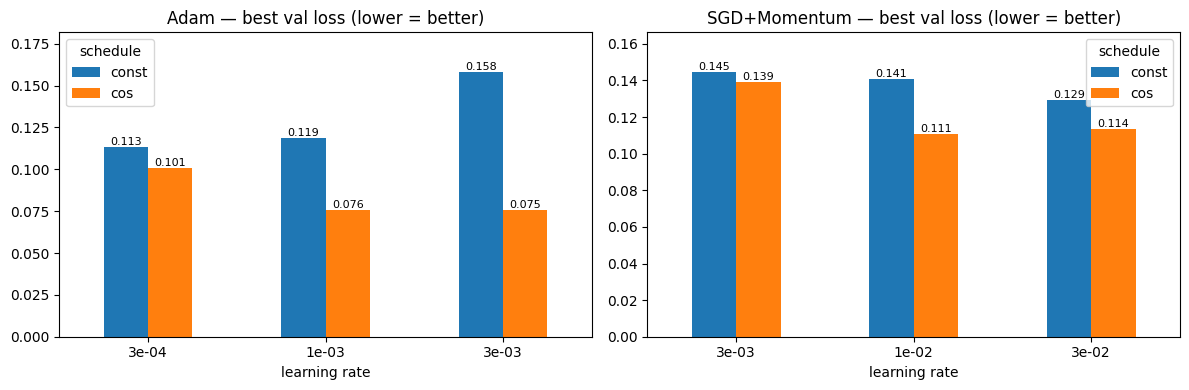

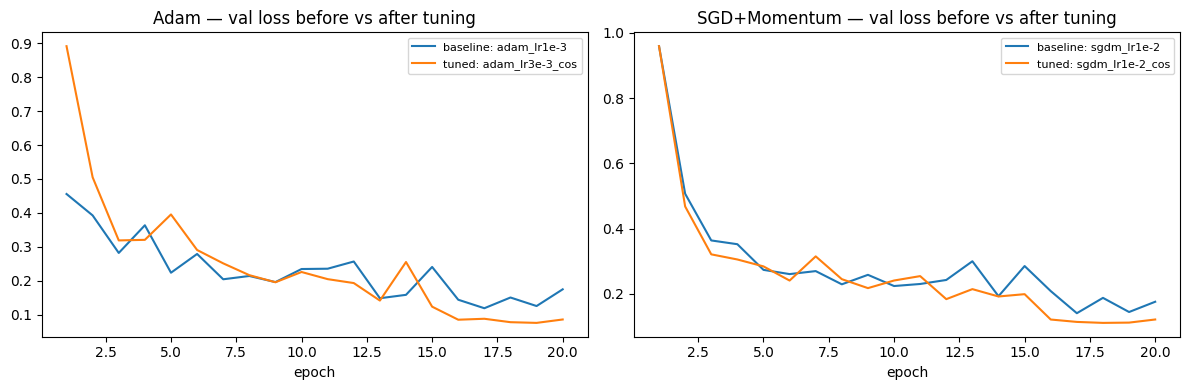

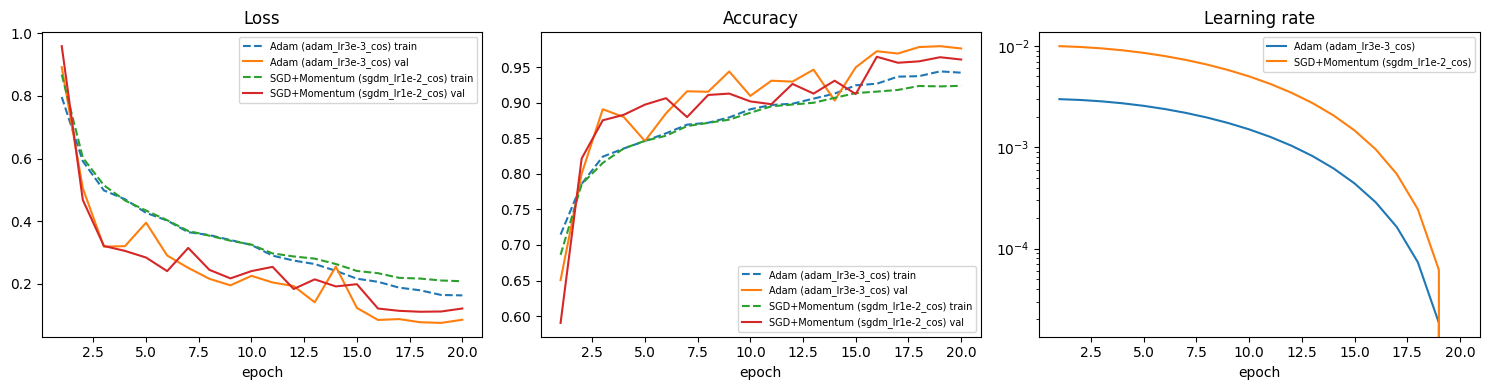

In [10]:
sweep = pd.DataFrame([{
    'run': n, 'optimizer': OPT_LABEL[r['optimizer']], 'lr': r['lr'], 'schedule': r['schedule'],
    'baseline': n in BASELINE.values(), 'epochs_run': len(r['hist']),
    'best_val_loss': r['hist'].val_loss.min(),
    'val_acc_at_best': r['hist'].val_acc[r['hist'].val_loss.idxmin()],
    'val_f1_at_best': r['hist'].val_f1[r['hist'].val_loss.idxmin()],
    'train_min': r['secs'] / 60} for n, r in runs.items()]).round(4)
sweep.to_csv(OUT/'05_tuning_sweep.csv', index=False)
display(sweep.sort_values(['optimizer', 'best_val_loss']))

TUNED = {o: sweep[sweep.run.map(lambda n: runs[n]['optimizer']) == o].sort_values('best_val_loss').run.iloc[0]
         for o in OPTS}
print('baseline:', BASELINE); print('tuned   :', TUNED)

# กราฟ 1: val loss ของทุก setup (ยิ่งต่ำยิ่งดี)
fig, axes = plt.subplots(1, len(OPTS), figsize=(12, 4), squeeze=False)
for ax, o in zip(axes[0], OPTS):
    d = sweep[sweep.run.map(lambda n: runs[n]['optimizer']) == o]
    piv = d.pivot_table(index='lr', columns='schedule', values='best_val_loss')
    piv.plot.bar(ax=ax, rot=0)
    ax.set_title(f'{OPT_LABEL[o]} — best val loss (lower = better)'); ax.set_xlabel('learning rate')
    ax.set_xticklabels([f'{v:.0e}' for v in piv.index]); ax.set_ylim(0, piv.max().max() * 1.15)
    for c in ax.containers: ax.bar_label(c, fmt='%.3f', fontsize=8)
plt.tight_layout(); plt.savefig(OUT/'06_lr_sweep.png', dpi=150); plt.show()

# กราฟ 2: ก่อน vs หลัง tuning (val loss ต่อ epoch)
fig, axes = plt.subplots(1, len(OPTS), figsize=(12, 4), squeeze=False)
for ax, o in zip(axes[0], OPTS):
    for n, lab in [(BASELINE[o], 'baseline'), (TUNED[o], 'tuned')]:
        h = runs[n]['hist']; ax.plot(h.epoch, h.val_loss, label=f'{lab}: {n}')
    ax.set_title(f'{OPT_LABEL[o]} — val loss before vs after tuning'); ax.set_xlabel('epoch'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT/'07_before_after_curves.png', dpi=150); plt.show()

# กราฟ 3: tuned Adam vs tuned SGD (train/val loss, accuracy, LR)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for o, n in TUNED.items():
    h = runs[n]['hist']; lab = f'{OPT_LABEL[o]} ({n})'
    ax[0].plot(h.epoch, h.train_loss, '--', label=f'{lab} train'); ax[0].plot(h.epoch, h.val_loss, label=f'{lab} val')
    ax[1].plot(h.epoch, h.train_acc, '--', label=f'{lab} train'); ax[1].plot(h.epoch, h.val_acc, label=f'{lab} val')
    ax[2].plot(h.epoch, h.lr, label=lab)
ax[2].set_yscale('log')
for a, t in zip(ax, ['Loss', 'Accuracy', 'Learning rate']): a.set_title(t); a.set_xlabel('epoch'); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT/'08_optimizer_curves.png', dpi=150); plt.show()

## 9. Clean test: ก่อน vs หลัง tuning
ประเมินบน **clean test** เท่านั้น (ตัดภาพที่มี near-duplicate อยู่ใน train ออกแล้ว) · 4 โมเดล: baseline + tuned ของแต่ละ optimizer

In [11]:
@torch.no_grad()
def ms_per_image(model, n=100):
    model.eval(); x = torch.randn(1, 3, S, S, device=DEVICE)
    for _ in range(10): model(x)
    if DEVICE == 'cuda': torch.cuda.synchronize()
    if DEVICE == 'mps': torch.mps.synchronize()
    t = time.time()
    for _ in range(n): model(x)
    if DEVICE == 'cuda': torch.cuda.synchronize()
    if DEVICE == 'mps': torch.mps.synchronize()
    return (time.time() - t) / n * 1000

rows, preds = [], {}
for o in OPTS:
    for stage, n in [('baseline', BASELINE[o]), ('tuned', TUNED[o])]:
        if n not in preds:
            preds[n] = predict(runs[n]['model'], dl_clean)[:2]
        y, p = preds[n]; m = metrics(y, p); r = runs[n]
        rows.append({'optimizer': OPT_LABEL[o], 'stage': stage, 'run': n, 'lr': r['lr'], 'schedule': r['schedule'],
                     'best_val_loss': r['hist'].val_loss.min(),
                     'clean_acc': m['acc'], 'clean_macroF1': m['macro_f1'],
                     'clean_rotten_recall': m['rotten_recall'], 'clean_false_reject': m['false_reject_rate']})
table = pd.DataFrame(rows).round(4)
table['params'] = n_params
table['ms_per_img'] = [round(ms_per_image(runs[n]['model']), 2) for n in table.run]
table.to_csv(OUT/'09_clean_test_comparison.csv', index=False)
display(table)

# โมเดลสุดท้าย (ใช้ใน web app): tuned ที่ val loss ต่ำสุด — เลือกจาก validation ไม่ใช่ test
best_name = min(TUNED.values(), key=lambda n: runs[n]['hist'].val_loss.min())
torch.save(runs[best_name]['model'].state_dict(), OUT/'best_model.pt')
print('final model (by val loss):', best_name, '→ outputs/best_model.pt')

,optimizer,stage,run,lr,schedule,best_val_loss,clean_acc,clean_macroF1,clean_rotten_recall,clean_false_reject,params,ms_per_img
0,Adam,baseline,adam_lr1e-3,0.001,const,0.1186,0.9558,0.9574,0.9826,0.0383,422566,1.72
1,Adam,tuned,adam_lr3e-3_cos,0.003,cos,0.0754,0.9704,0.9709,0.9834,0.0272,422566,1.11
2,SGD+Momentum,baseline,sgdm_lr1e-2,0.010,const,0.1406,0.9513,0.9522,0.9748,0.0332,422566,1.13
3,SGD+Momentum,tuned,sgdm_lr1e-2_cos,0.010,cos,0.1109,0.9544,0.9552,0.9724,0.0292,422566,1.12


final model (by val loss): adam_lr3e-3_cos → outputs/best_model.pt


## 10. Confusion matrix + per-class report (tuned models, clean test)

=== Adam — adam_lr3e-3_cos (clean test) ===
               precision    recall  f1-score   support

  freshapples      0.957     0.969     0.963       322
  freshbanana      0.994     0.997     0.995       326
 freshoranges      0.985     0.954     0.969       345
 rottenapples      0.962     0.948     0.955       504
 rottenbanana      0.988     0.998     0.993       417
rottenoranges      0.938     0.963     0.950       347

     accuracy                          0.970      2261
    macro avg      0.971     0.971     0.971      2261
 weighted avg      0.971     0.970     0.970      2261

=== SGD+Momentum — sgdm_lr1e-2_cos (clean test) ===
               precision    recall  f1-score   support

  freshapples      0.951     0.957     0.954       322
  freshbanana      0.982     0.991     0.986       326
 freshoranges      0.960     0.962     0.961       345
 rottenapples      0.927     0.937     0.932       504
 rottenbanana      0.974     0.995     0.985       417
rottenoranges      0

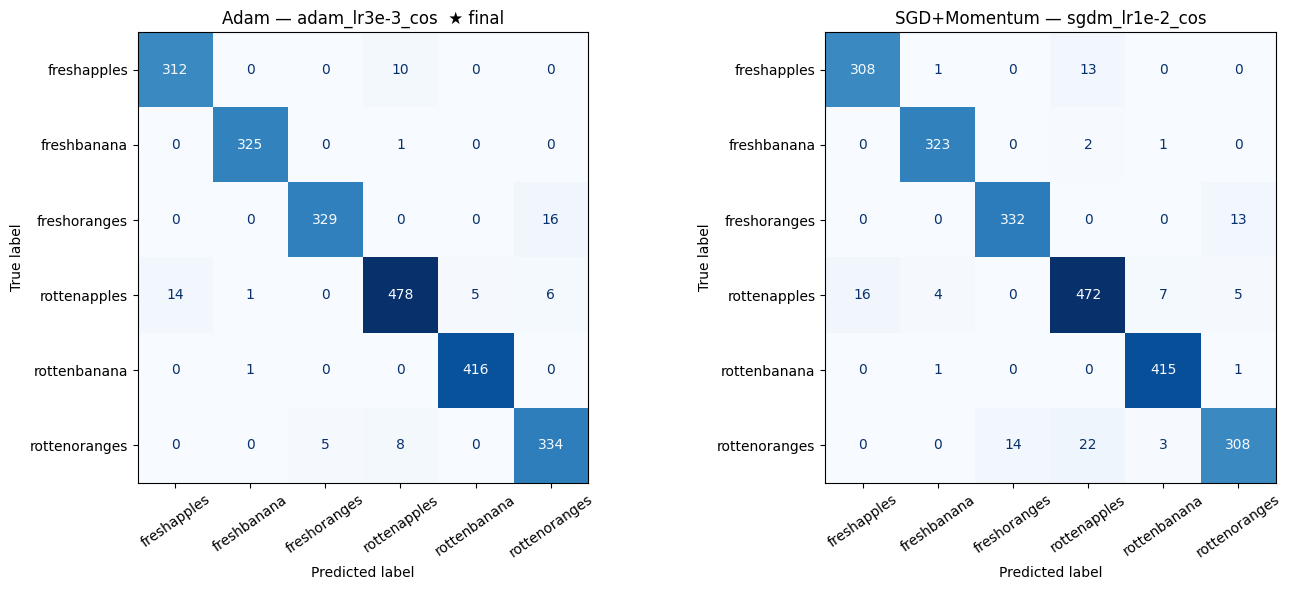

In [12]:
fig, axes = plt.subplots(1, len(TUNED), figsize=(14, 6), squeeze=False)
for ax, (o, n) in zip(axes[0], TUNED.items()):
    y, p = preds[n]; pred = p.argmax(1)
    print(f'=== {OPT_LABEL[o]} — {n} (clean test) ===')
    print(classification_report(y, pred, target_names=CLASSES, digits=3))
    ConfusionMatrixDisplay(confusion_matrix(y, pred, labels=range(len(CLASSES))), display_labels=CLASSES).plot(
        ax=ax, xticks_rotation=35, cmap='Blues', colorbar=False)
    ax.set_title(f'{OPT_LABEL[o]} — {n}' + ('  ★ final' if n == best_name else ''))
plt.tight_layout(); plt.savefig(OUT/'10_confusion_matrix_clean.png', dpi=150); plt.show()

## 11. ภาพที่ทายผิด (โมเดลสุดท้าย, clean test)

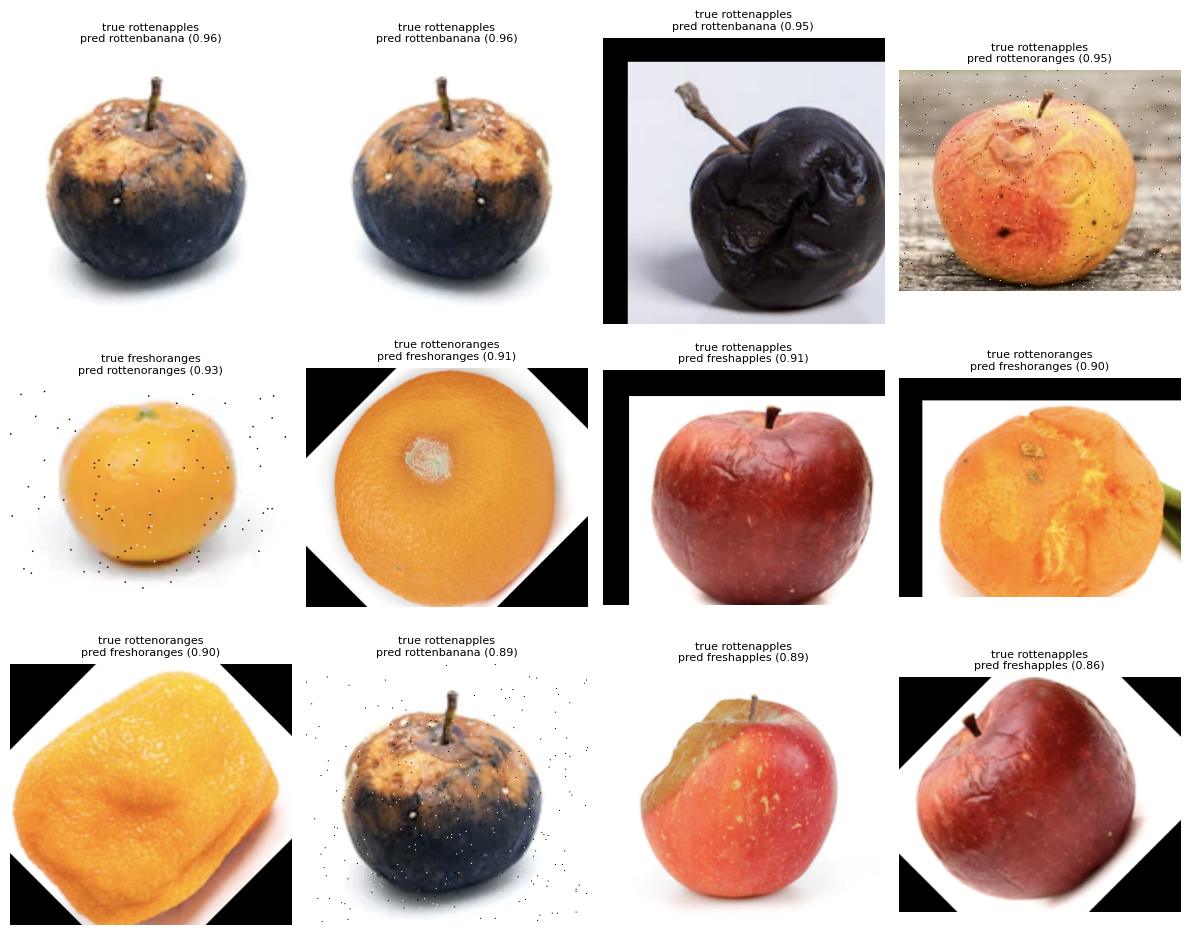

In [13]:
y, p = preds[best_name]; pred = p.argmax(1)
wrong = np.nonzero(pred != y)[0]
wrong = wrong[np.argsort(-p[wrong].max(1))][:12]   # ผิดแบบมั่นใจสูงสุดก่อน
paths = clean_test_df.path.tolist()                 # ลำดับเดียวกับ dl_clean
if len(wrong):
    cols = 4; rows_ = math.ceil(len(wrong) / cols)
    fig, axes = plt.subplots(rows_, cols, figsize=(12, 3.2 * rows_), squeeze=False)
    for a in axes.flat: a.axis('off')
    for a, i in zip(axes.flat, wrong):
        a.imshow(Image.open(paths[i]).convert('RGB'))
        a.set_title(f'true {CLASSES[y[i]]}\npred {CLASSES[pred[i]]} ({p[i].max():.2f})', fontsize=8)
    plt.tight_layout(); plt.savefig(OUT/'11_misclassified.png', dpi=120); plt.show()
else:
    print('no errors on clean test')

## 12. บันทึกสรุป (ใช้เขียน report / slides)

In [14]:
summary = dict(config=CFG, device=DEVICE,
               split_sizes=dict(train=len(train_df), val=len(val_df), test=len(test_df), clean_test=len(clean_test_df)),
               duplicates=dup_stats, baseline=BASELINE, tuned=TUNED, final_model=best_name,
               tuning_sweep=sweep.to_dict(orient='records'),
               clean_test=table.to_dict(orient='records'))
(OUT/'results.json').write_text(json.dumps(summary, indent=2, default=str))
print(json.dumps({k: summary[k] for k in ['baseline', 'tuned', 'final_model']}, indent=2))
display(table)
print('saved to', OUT.resolve())

{
  "baseline": {
    "adam": "adam_lr1e-3",
    "sgdm": "sgdm_lr1e-2"
  },
  "tuned": {
    "adam": "adam_lr3e-3_cos",
    "sgdm": "sgdm_lr1e-2_cos"
  },
  "final_model": "adam_lr3e-3_cos"
}


,optimizer,stage,run,lr,schedule,best_val_loss,clean_acc,clean_macroF1,clean_rotten_recall,clean_false_reject,params,ms_per_img
0,Adam,baseline,adam_lr1e-3,0.001,const,0.1186,0.9558,0.9574,0.9826,0.0383,422566,1.72
1,Adam,tuned,adam_lr3e-3_cos,0.003,cos,0.0754,0.9704,0.9709,0.9834,0.0272,422566,1.11
2,SGD+Momentum,baseline,sgdm_lr1e-2,0.010,const,0.1406,0.9513,0.9522,0.9748,0.0332,422566,1.13
3,SGD+Momentum,tuned,sgdm_lr1e-2_cos,0.010,cos,0.1109,0.9544,0.9552,0.9724,0.0292,422566,1.12


saved to /kaggle/working/outputs
